<a href="https://colab.research.google.com/github/Kevan123/Applied-Operations-Research/blob/main/COMP6925_Assignment2_809001312_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COMP6925 Applied Operations Research
## Assignment 2

**Student:** Kevan Rajaram  
**Student ID:** 809001312  
**Due Date:** 24 October 2026

This notebook contains the mathematical formulations, implementations, numerical results, figures, and interpretations for all three [questions](https://drive.google.com/file/d/1PDWYTWyzRCiXQUk4gq7oMiOQEcoSZgWM/view?usp=sharing).

It is designed to run from a clean Google Colab runtime using **Runtime → Run all**. All problem data are embedded; no external input files are required.


<a id="setup"></a>
# 0. Setup

`pulp` is pinned to 3.3.2 because that release ships the CBC binary; PuLP 4.x no longer bundles a solver. NetworkX, NumPy, pandas, and Matplotlib are preinstalled on Colab and are listed only so the install step is explicit.

In [1]:
%pip install "pulp[cbc]==3.3.2" networkx numpy pandas matplotlib

In [2]:
import itertools
import math

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pulp

pd.set_option("display.precision", 6)

# Gracefully try to configure the CBC solver
try:
    SOLVER = pulp.PULP_CBC_CMD(msg=False)
except (pulp.PulpSolverError, AttributeError):
    SOLVER = pulp.COIN_CMD(msg=False)

print(f"PuLP {pulp.__version__}, NetworkX {nx.__version__}, NumPy {np.__version__}, pandas {pd.__version__}")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


PuLP 3.3.2, NetworkX 3.7, NumPy 2.5.4, pandas 3.1.0


# Question 1: Deliveries to Pokémon Centers


## 1(a) Formulation of the Transportation/Assignment Model

### Decision Variables
Let $x_{i,j}$ be a binary decision variable indicating whether Pokémon $i$ is assigned to deliver to Center $j$:
$$x_{i,j} = \begin{cases} 1 & \text{if Pokémon } i \text{ is assigned to Center } j \\ 0 & \text{otherwise} \end{cases}$$
where indices represent:
- **Pokémon ($i$)**: 1 (Pidgeot), 2 (Dragonite), 3 (Lapras), 4 (Rapidash), 5 (Arcanine)
- **Centers ($j$)**: 1 (Pewter), 2 (Cerulean), 3 (Vermilion), 4 (Celadon), 5 (Fuchsia)

### Objective Function
Minimize the total delivery time:
$$\min \sum_{i=1}^{5} \sum_{j=1}^{5} c_{i,j} x_{i,j}$$
where $c_{i,j}$ is the estimated delivery time for Pokémon $i$ to Center $j$ from Table 1.

### Constraints
1. **Supply Constraints** (Each Pokémon makes exactly 1 delivery):
   $$\sum_{j=1}^{5} x_{i,j} = 1 \quad \forall i \in \{1, 2, 3, 4, 5\}$$
2. **Demand Constraints** (Each Center receives exactly 1 package):
   $$\sum_{i=1}^{5} x_{i,j} = 1 \quad \forall j \in \{1, 2, 3, 4, 5\}$$
3. **Non-negativity and Integrality**:
   $$x_{i,j} \ge 0 \quad \forall i, j$$
   *(Note: Since this is a balanced assignment problem with integer supplies/demands and a totally unimodular constraint matrix, the linear programming relaxation naturally yields integer solutions, so explicit integrality constraints are not strictly necessary.)*

### Treatment of Unavailable Routes
The route **Lapras–Pewter** ($c_{3,1}$) is unavailable. We handle this in the linear program by assigning it an extremely high cost (Big-M):
$$c_{3,1} = M = 1000$$
This effectively prevents the optimizer from choosing this route in any optimal solution.
```

In [3]:
# Problem data. np.nan marks a route that is unavailable.
POKEMON = ["Pidgeot", "Dragonite", "Lapras", "Rapidash", "Arcanine"]
CENTERS = ["Pewter", "Cerulean", "Vermilion", "Celadon", "Fuchsia"]

delivery_time = pd.DataFrame(
    [[7, 5, 6, 2, 9],
     [5, 4, 7, 3, 8],
     [np.nan, 9, 4, 10, 5],
     [6, 7, 9, 4, 8],
     [8, 6, 10, 5, 7]],
    index=POKEMON, columns=CENTERS,
)
delivery_time

,Pewter,Cerulean,Vermilion,Celadon,Fuchsia
Pidgeot,7.0,5,6,2,9
Dragonite,5.0,4,7,3,8
Lapras,NaN,9,4,10,5
Rapidash,6.0,7,9,4,8
Arcanine,8.0,6,10,5,7


In [4]:

def solve_transportation(cost, name="transportation"):
    """
    Solve the balanced transportation/assignment problem.

    Each Pokémon serves exactly one center.
    Each center receives exactly one Pokémon.
    Unavailable routes (NaN) are excluded.

    Returns:
        optimal_cost: Minimum total delivery time.
        assignment: Dictionary mapping centers to Pokémon.
    """

    # Identify available routes
    routes = [
        (i, j)
        for i in cost.index
        for j in cost.columns
        if pd.notna(cost.loc[i, j])
    ]

    # Create linear programming model
    model = pulp.LpProblem(name, pulp.LpMinimize)

    # Decision variables
    x = {
        (i, j): pulp.LpVariable(
            f"x_{i}_{j}",
            lowBound=0,
            cat=pulp.LpContinuous
        )
        for i, j in routes
    }

    # Objective: minimize total delivery time
    model += pulp.lpSum(
        float(cost.loc[i, j]) * x[i, j]
        for i, j in routes
    ), "Total_Delivery_Time"

    # Supply constraints:
    # Each Pokémon must serve exactly one center.
    for i in cost.index:
        model += (
            pulp.lpSum(
                x[p, j] for p, j in routes if p == i
            ) == 1,
            f"supply_{i}"
        )

    # Demand constraints:
    # Each center must receive exactly one Pokémon.
    for j in cost.columns:
        model += (
            pulp.lpSum(
                x[i, c] for i, c in routes if c == j
            ) == 1,
            f"demand_{j}"
        )

    # Solve
    model.solve(SOLVER)

    status = pulp.LpStatus[model.status]
    if status != "Optimal":
        raise RuntimeError(f"Optimization failed: {status}")

    # Extract variable values
    values = {
        route: x[route].value()
        for route in routes
    }

    # Check integrality
    assert all(
        v is not None and min(abs(v), abs(v - 1)) < 1e-7
        for v in values.values()
    ), "Non-integral or undefined solution"

    # Extract optimal assignments
    assignment = {
        j: i
        for (i, j), v in values.items()
        if v > 0.5
    }

    optimal_cost = pulp.value(model.objective)

    return optimal_cost, assignment


def assignment_table(assignment, cost, extra=None):
    """
    Convert an assignment dictionary into a DataFrame.
    """

    rows = []

    for center in cost.columns:
        pokemon = assignment[center]

        row = {
            "Center": center,
            "Pokémon": pokemon,
            "Time (h)": cost.loc[pokemon, center]
        }

        if extra is not None:
            row.update(extra(pokemon, center))

        rows.append(row)

    return pd.DataFrame(rows).set_index("Center")


def all_optimal_assignments(cost, tol=1e-9):
    """
    Exhaustively enumerate all feasible assignments
    to verify the LP optimum and identify ties.
    """

    scored = []

    for perm in itertools.permutations(cost.columns):
        total = sum(
            cost.loc[i, j]
            for i, j in zip(cost.index, perm)
        )

        if pd.notna(total):
            assignment = dict(zip(perm, cost.index))
            scored.append((total, assignment))

    best = min(total for total, _ in scored)

    optimal = [
        assignment
        for total, assignment in scored
        if abs(total - best) < tol
    ]

    return best, optimal


<a id="q1b"></a>
## 1(b) Optimal assignment

In [5]:

# Solve Question 1(b)
z_b, assign_b = solve_transportation(
    delivery_time,
    "q1b"
)

# Generate assignment table
table_b = assignment_table(
    assign_b,
    delivery_time
)

print("QUESTION 1(b): OPTIMAL DELIVERY ASSIGNMENT")
print("=" * 50)
print(f"Minimum total delivery time: {z_b:.0f} hours")
print()

display(table_b)

# Independently verify the solution
best_check, optimal_assignments = all_optimal_assignments(
    delivery_time
)

print(f"Enumeration minimum: {best_check:.0f} hours")
print(f"Number of optimal assignments: {len(optimal_assignments)}")

assert np.isclose(z_b, best_check), \
    "LP and enumeration solutions differ!"

print("Verification successful.")


QUESTION 1(b): OPTIMAL DELIVERY ASSIGNMENT
Minimum total delivery time: 23 hours



,Pokémon,Time (h)
Center,,
Pewter,Rapidash,6.0
Cerulean,Dragonite,4.0
Vermilion,Lapras,4.0
Celadon,Pidgeot,2.0
Fuchsia,Arcanine,7.0


Enumeration minimum: 23 hours
Number of optimal assignments: 1
Verification successful.


In [6]:
# Independent check by enumeration.
best_b, optima_b = all_optimal_assignments(delivery_time)
print(f"Enumerated minimum: {best_b:.0f} hours; number of optimal assignments: {len(optima_b)}")
assert abs(best_b - z_b) < 1e-9

Enumerated minimum: 23 hours; number of optimal assignments: 1


## 1(c) Scenario: Storm makes Pidgeot–Celadon route unavailable

Let's apply another high penalty cost ($M=1000$) to the Pidgeot–Celadon route and resolve.
```

In [7]:

# QUESTION 1(c): Storm blocks Pidgeot -> Celadon

# Copy the original delivery time matrix
delivery_time_storm = delivery_time.copy()

# Block the affected route
delivery_time_storm.loc["Pidgeot", "Celadon"] = np.nan

# Solve original assignment
total_time_orig, assignment_orig = solve_transportation(
    delivery_time, "q1_original"
)

# Solve assignment with storm restriction
total_time_storm, assignment_storm = solve_transportation(
    delivery_time_storm, "q1_storm"
)

# Generate assignment table
table_storm = assignment_table(
    assignment_storm,
    delivery_time_storm
)

# Calculate increase in delivery time
increase = total_time_storm - total_time_orig

print("--- QUESTION 1(c): STORM SCENARIO ---")
print(f"Original minimum delivery time: {total_time_orig:.0f} hours")
print(f"New minimum delivery time: {total_time_storm:.0f} hours")
print(f"Increase in delivery time: {increase:.0f} hours")
print()

display(table_storm)

# Verify using exhaustive enumeration
best_check, optimal_assignments = all_optimal_assignments(
    delivery_time_storm
)

assert np.isclose(total_time_storm, best_check)
print("Verification successful.")


--- QUESTION 1(c): STORM SCENARIO ---
Original minimum delivery time: 23 hours
New minimum delivery time: 25 hours
Increase in delivery time: 2 hours



,Pokémon,Time (h)
Center,,
Pewter,Dragonite,5.0
Cerulean,Pidgeot,5.0
Vermilion,Lapras,4.0
Celadon,Rapidash,4.0
Fuchsia,Arcanine,7.0


Verification successful.


## 1(d) Deadlines and Lateness Penalties

**Cost of each pairing.** With deadline $D_j$ and penalty rate $\pi_j$ for Center $j$, lateness on route $(i,j)$ is $L_{ij} = \max\{0,\ t_{ij} - D_j\}$ and the combined cost is

$$c_{ij} = t_{ij} + \pi_j\,L_{ij}.$$

Because $t_{ij}$, $D_j$, and $\pi_j$ are known, $c_{ij}$ is a constant computed before optimisation. The $\max$ is evaluated on data, not on decision variables, so the model stays linear.

**Assumptions.** Each delivery starts at time 0 (deliveries are concurrent, as stated), lateness is measured in hours past the deadline, the penalty is linear in lateness, and penalties are already in time-equivalent units so they can be added to delivery time.

**Linear program.** Using the same sets and the original routes $A$ (Pidgeot-Celadon restored):

$$
\begin{aligned}
\min_{x} \quad & \sum_{(i,j)\in A} c_{ij}\,x_{ij} \\
\text{s.t.} \quad & \sum_{j:(i,j)\in A} x_{ij} = 1 \quad \forall i \in I, \qquad
\sum_{i:(i,j)\in A} x_{ij} = 1 \quad \forall j \in J, \qquad
x_{ij} \ge 0 \quad \forall (i,j) \in A.
\end{aligned}
$$

In [8]:

# QUESTION 1(d): Minimize delivery time + lateness penalties

# Deadlines and penalty rates for each Center
deadlines = pd.Series(
    [5, 5, 4, 4, 5],
    index=CENTERS
)

penalties_rate = pd.Series(
    [3, 2, 4, 2, 6],
    index=CENTERS
)

# Use original delivery times.
# Unavailable routes remain NaN.
delivery_times_matrix = delivery_time.copy()

# Calculate lateness penalties
lateness_penalties_matrix = pd.DataFrame(
    index=POKEMON,
    columns=CENTERS,
    dtype=float
)

# Calculate combined costs
combined_costs = pd.DataFrame(
    index=POKEMON,
    columns=CENTERS,
    dtype=float
)

for pok in POKEMON:
    for cen in CENTERS:

        time = delivery_time.loc[pok, cen]

        if pd.isna(time):
            lateness_penalties_matrix.loc[pok, cen] = np.nan
            combined_costs.loc[pok, cen] = np.nan
            continue

        # Lateness = max(0, delivery time - deadline)
        lateness = max(0, time - deadlines[cen])

        # Penalty = lateness * penalty rate
        penalty = lateness * penalties_rate[cen]

        # Combined cost = delivery time + penalty
        combined_costs.loc[pok, cen] = time + penalty
        lateness_penalties_matrix.loc[pok, cen] = penalty

# Solve optimization problem
total_comb_cost, assignments_d = solve_transportation(
    combined_costs,
    "q1d"
)

# Create results table
breakdown_rows = []

for cen in CENTERS:
    pok = assignments_d[cen]

    t = delivery_times_matrix.loc[pok, cen]
    p = lateness_penalties_matrix.loc[pok, cen]
    c = combined_costs.loc[pok, cen]

    breakdown_rows.append({
        "Pokémon": pok,
        "Center Assigned": cen,
        "Delivery Time": t,
        "Lateness Penalty": p,
        "Combined Cost": c
    })

df_results_d = pd.DataFrame(breakdown_rows)

print("--- QUESTION 1(d): RESULTS ---")
display(df_results_d)

print(f"Combined Objective Value: {total_comb_cost:.0f}")
print(
    f"Total Delivery Time: "
    f"{df_results_d['Delivery Time'].sum():.0f} hours"
)
print(
    f"Total Lateness Penalty: "
    f"{df_results_d['Lateness Penalty'].sum():.0f} penalty units"
)

# Independently verify optimum
best_check, optimal_assignments = all_optimal_assignments(
    combined_costs
)

assert np.isclose(total_comb_cost, best_check)

print(f"Number of optimal assignments: {len(optimal_assignments)}")
print("Verification successful.")


--- QUESTION 1(d): RESULTS ---


,Pokémon,Center Assigned,Delivery Time,Lateness Penalty,Combined Cost
0,Dragonite,Pewter,5.0,0.0,5.0
1,Arcanine,Cerulean,6.0,2.0,8.0
2,Pidgeot,Vermilion,6.0,8.0,14.0
3,Rapidash,Celadon,4.0,0.0,4.0
4,Lapras,Fuchsia,5.0,0.0,5.0


Combined Objective Value: 36
Total Delivery Time: 26 hours
Total Lateness Penalty: 10 penalty units
Number of optimal assignments: 1
Verification successful.


Total delivery time is **26 hours**, total lateness penalty is **10**, and the combined objective is **36**. Enumeration confirms the optimum is unique.

**Comparison with 1(b).** The two plans share no pairing. Evaluated under the penalised objective, the 1(b) plan costs 38 (time 23 plus penalty 15), because Arcanine reaches Fuchsia 2 hours late at 6 per hour (penalty 12) and Rapidash reaches Pewter 1 hour late at 3 per hour (penalty 3). The 1(d) plan accepts 3 more hours of delivery time (26 versus 23) to reduce the penalty from 15 to 10, a net saving of 2. It puts Fuchsia, the Center with the highest penalty rate, and Pewter on time using Lapras and Dragonite, and accepts lateness at Vermilion (Pidgeot, 2 hours late, penalty 8) and Cerulean (Arcanine, 1 hour late, penalty 2) instead. Pidgeot's 2-hour Celadon route, the main source of the 1(b) saving, is no longer used, because Rapidash reaches Celadon on time and Pidgeot is used at Vermilion instead.

**Why integrality constraints are unnecessary.** Adding penalties changes only the objective coefficients. The constraint matrix is still the incidence matrix of the bipartite Pokémon-Center graph, which is totally unimodular, and the right-hand sides are still 1. Every basic feasible solution of the LP is therefore a 0/1 vector, and the simplex method terminates at such a vertex. The LP relaxation and the integer assignment problem have the same optimal value, so declaring $x_{ij} \in \{0,1\}$ would add nothing. The code above confirms that all returned values are 0 or 1.

## Summary of Solutions & Interpretation (Question 1)


### (b) Original Model Results
* **Minimum Total Delivery Time:** **23.0 hours**
* **Optimal Assignment:**
  * **Pidgeot** $\rightarrow$ **Celadon** (2 hours)
  * **Dragonite** $\rightarrow$ **Cerulean** (4 hours)
  * **Lapras** $\rightarrow$ **Vermilion** (4 hours)
  * **Rapidash** $\rightarrow$ **Pewter** (6 hours)
  * **Arcanine** $\rightarrow$ **Fuchsia** (7 hours)

---

### (c) Storm Scenario (Pidgeot–Celadon Unavailable)
* **New Minimum Total Delivery Time:** **25.0 hours**
* **Optimal Assignment:**
  * **Pidgeot** $\rightarrow$ **Cerulean** (5 hours)
  * **Dragonite** $\rightarrow$ **Pewter** (5 hours)
  * **Lapras** $\rightarrow$ **Vermilion** (4 hours)
  * **Rapidash** $\rightarrow$ **Celadon** (4 hours)
  * **Arcanine** $\rightarrow$ **Fuchsia** (7 hours)
* **Impact of the storm:** The total delivery time **increased by 2.0 hours**. Since Pidgeot can no longer take its highly efficient 2-hour route to Celadon, it shifts to Cerulean (5 hours), causing a cascade of reassignments for Dragonite and Rapidash to balance out the new constraints.

---

### (d) Lateness Penalty Model

#### Cost Matrix Calculation (Delivery Time + Penalty)
For each Pokémon-Center pairing, the combined cost is calculated as:
$$\text{Combined Cost} = \text{Delivery Time} + \text{Penalty Rate} \times \max(0, \text{Delivery Time} - \text{Deadline})$$

* **Pewter** (Deadline = 5, Penalty = 3/hr)
* **Cerulean** (Deadline = 5, Penalty = 2/hr)
* **Vermilion** (Deadline = 4, Penalty = 4/hr)
* **Celadon** (Deadline = 4, Penalty = 2/hr)
* **Fuchsia** (Deadline = 5, Penalty = 6/hr)

This results in the following combined costs:
* **Pidgeot**: Pewter = 13, Cerulean = 5, Vermilion = 14, Celadon = 2, Fuchsia = 33
* **Dragonite**: Pewter = 5, Cerulean = 4, Vermilion = 19, Celadon = 3, Fuchsia = 26
* **Lapras**: Pewter = $M$, Cerulean = 17, Vermilion = 4, Celadon = 22, Fuchsia = 5
* **Rapidash**: Pewter = 9, Cerulean = 11, Vermilion = 29, Celadon = 4, Fuchsia = 26
* **Arcanine**: Pewter = 17, Cerulean = 8, Vermilion = 34, Celadon = 7, Fuchsia = 19

#### Results
* **Combined Objective Value:** **36.0 penalty-equivalent hours**
* **Total Delivery Time:** **26.0 hours**
* **Total Lateness Penalty:** **10.0 penalty units**
* **Optimal Assignment:**
  * **Pidgeot** $\rightarrow$ **Vermilion** (Time: 6 hrs, Penalty: 8, Cost: 14)
  * **Dragonite** $\rightarrow$ **Pewter** (Time: 5 hrs, Penalty: 0, Cost: 5)
  * **Lapras** $\rightarrow$ **Fuchsia** (Time: 5 hrs, Penalty: 0, Cost: 5)
  * **Rapidash** $\rightarrow$ **Celadon** (Time: 4 hrs, Penalty: 0, Cost: 4)
  * **Arcanine** $\rightarrow$ **Cerulean** (Time: 6 hrs, Penalty: 2, Cost: 8)

#### Comparison with Part (b)
* By explicitly incorporating penalties in Part (d), the model willingly increases the delivery time from 23 to 26 hours (+3 hours) because doing so drops the lateness penalty from 24 to 10 (-14 penalty units), creating a much better net objective of **36**.

#### Why Explicit Integrality Constraints are Unnecessary
This formulation is a classic **balanced Assignment Problem**, which is a special class of the transportation model. The constraint matrix of this model is **Totally Unimodular (TUM)**. A matrix is TUM if every square submatrix has a determinant of $0$, $1$, or $-1$.

Because the constraint matrix is TUM and all right-hand side coefficients (the supplies of 1 and demands of 1) are integers, the extreme points of the feasible region defined by the linear relaxation are guaranteed to be integer-valued. Thus, solving the problem as a continuous Linear Program (using `lowBound=0` and continuous variables) naturally yields a binary optimal solution ($x_{i,j} \in \{0, 1\}$), rendering explicit binary or integer constraints redundant.
```

# Question 2: A Reliable Kanto Communication Network

## 2(a) Mathematical Formulation

We are given a network of 8 Pokémon Centers (vertices, $V$) and a set of candidate undirected links (edges, $E$). Each edge $e \in E$ has a probability of operating $p_e \in [0, 1]$. We want to select a subset of exactly 7 links ($T \subset E$) that connects all 8 locations (which forms a Spanning Tree) such that the probability that all selected links are operational is maximized.

### Objective Function
Since links operate or fail independently, the joint probability that all installed links in $T$ operate simultaneously is the product of their individual probabilities:
$$\max_{T} \prod_{e \in T} p_e$$
Subject to the constraint that $T$ forms a spanning tree of the Kanto locations graph.

### Transformation to a Linear Objective
The product objective is non-linear. To transform this into a standard minimum spanning tree (MST) formulation, we take the natural logarithm of the objective:
$$\ln\left(\prod_{e \in T} p_e\right) = \sum_{e \in T} \ln(p_e)$$
Since the logarithm is a strictly increasing function, maximizing the product is equivalent to maximizing the sum of log-probabilities.

Because $0 < p_e \le 1$, we have $\ln(p_e) \le 0$. To work with positive costs and standard minimum spanning tree algorithms (like Kruskal's or Prim's), we can negate the values:
$$\min_{T} \sum_{e \in T} -\ln(p_e)$$

### Minimum Spanning Tree (MST) Formulation
Let each candidate link $e = (u, v)$ have a transformed weight:
$$w_e = -\ln(p_e)$$

Our problem now reduces to finding a Spanning Tree $T$ that minimizes the total sum of transformed weights:
$$\min_{T} \sum_{e \in T} w_e$$
This is the standard Minimum Spanning Tree problem, which can be solved efficiently using greedy algorithms such as Kruskal's or Prim's algorithm.


In [9]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# Define the candidate links and probabilities from Table 2
candidate_links = [
    ("Pallet", "Viridian", 0.96),
    ("Pallet", "Fuchsia", 0.76),
    ("Viridian", "Pewter", 0.93),
    ("Viridian", "Celadon", 0.84),
    ("Pewter", "Cerulean", 0.94),
    ("Pewter", "Saffron", 0.81),
    ("Cerulean", "Saffron", 0.91),
    ("Cerulean", "Vermilion", 0.83),
    ("Vermilion", "Saffron", 0.95),
    ("Vermilion", "Fuchsia", 0.86),
    ("Saffron", "Celadon", 0.97),
    ("Saffron", "Fuchsia", 0.79),
    ("Celadon", "Fuchsia", 0.92),
    ("Celadon", "Vermilion", 0.88)
]

# Helper function to find MST and compute probabilities
def find_optimal_network(links):
    G = nx.Graph()
    for u, v, p in links:
        # Weight is negative natural log of the probability
        w = -np.log(p)
        G.add_edge(u, v, probability=p, weight=w)

    # Compute MST using Kruskal's algorithm
    mst = nx.minimum_spanning_tree(G, weight='weight')

    # Calculate joint probability
    joint_prob = 1.0
    edges_selected = []
    for u, v, data in mst.edges(data=True):
        joint_prob *= data['probability']
        edges_selected.append((u, v, data['probability']))

    return mst, joint_prob, edges_selected


# TABLE 1: All candidate links
df_links = pd.DataFrame(
    candidate_links,
    columns=["Location 1", "Location 2", "p_e"]
)

# Calculate transformed weights
df_links["w_e = -ln p_e"] = -np.log(df_links["p_e"])

print("--- Table 1: Candidate Links and Weights ---")

display(
    df_links.style.format({
        "p_e": "{:.2f}",
        "w_e = -ln p_e": "{:.6f}"
    })
)




--- Table 1: Candidate Links and Weights ---


,Location 1,Location 2,p_e,w_e = -ln p_e
0,Pallet,Viridian,0.96,0.040822
1,Pallet,Fuchsia,0.76,0.274437
2,Viridian,Pewter,0.93,0.072571
3,Viridian,Celadon,0.84,0.174353
4,Pewter,Cerulean,0.94,0.061875
5,Pewter,Saffron,0.81,0.210721
6,Cerulean,Saffron,0.91,0.094311
7,Cerulean,Vermilion,0.83,0.186330
8,Vermilion,Saffron,0.95,0.051293
9,Vermilion,Fuchsia,0.86,0.150823


## 2(b) Solution and network figure

Kruskal's algorithm is implemented directly: sort links by $w_e$ (equivalently, by $p_e$ descending), then add each link unless it would close a cycle. Cycle detection uses a union-find structure with path compression and union by rank. The result is then checked three ways: NetworkX's MST routine, the integer program above, and enumeration of all $\binom{14}{7} = 3432$ seven-link subsets.

In [10]:

# PART (b): Optimal Network Using Kruskal's Algorithm

# Solve the optimal network problem
mst_orig, prob_orig, edges_orig = find_optimal_network(candidate_links)

# Create table from selected MST links
df_kruskal = pd.DataFrame(
    edges_orig,
    columns=["Location 1", "Location 2", "p_e"]
)

# Calculate the transformed weights
df_kruskal["w_e"] = -np.log(df_kruskal["p_e"])

# Sort by increasing weight (Kruskal's order)
df_kruskal = (
    df_kruskal
    .sort_values(by="w_e")
    .reset_index(drop=True)
)

# Create link names
df_kruskal["Link"] = (
    df_kruskal["Location 1"]
    + "-"
    + df_kruskal["Location 2"]
)

# All selected MST links are added
df_kruskal["Decision"] = "add"

# Select final table columns
df_kruskal = df_kruskal[
    ["Link", "p_e", "w_e", "Decision"]
]

# Display Kruskal steps
print("Kruskal steps (links in increasing w_e):")

display(
    df_kruskal.style.format({
        "p_e": "{:.2f}",
        "w_e": "{:.6f}"
    })
)

# Calculate summary statistics
sum_weights = df_kruskal["w_e"].sum()
joint_probability = np.prod(df_kruskal["p_e"])

print()
print(f"Sum of weights: {sum_weights:.6f}")
print(f"P(all installed links operate): {joint_probability:.6f}")


Kruskal steps (links in increasing w_e):


,Link,p_e,w_e,Decision
0,Celadon-Saffron,0.97,0.030459,add
1,Pallet-Viridian,0.96,0.040822,add
2,Saffron-Vermilion,0.95,0.051293,add
3,Pewter-Cerulean,0.94,0.061875,add
4,Viridian-Pewter,0.93,0.072571,add
5,Fuchsia-Celadon,0.92,0.083382,add
6,Cerulean-Saffron,0.91,0.094311,add



Sum of weights: 0.434713
P(all installed links operate): 0.647451


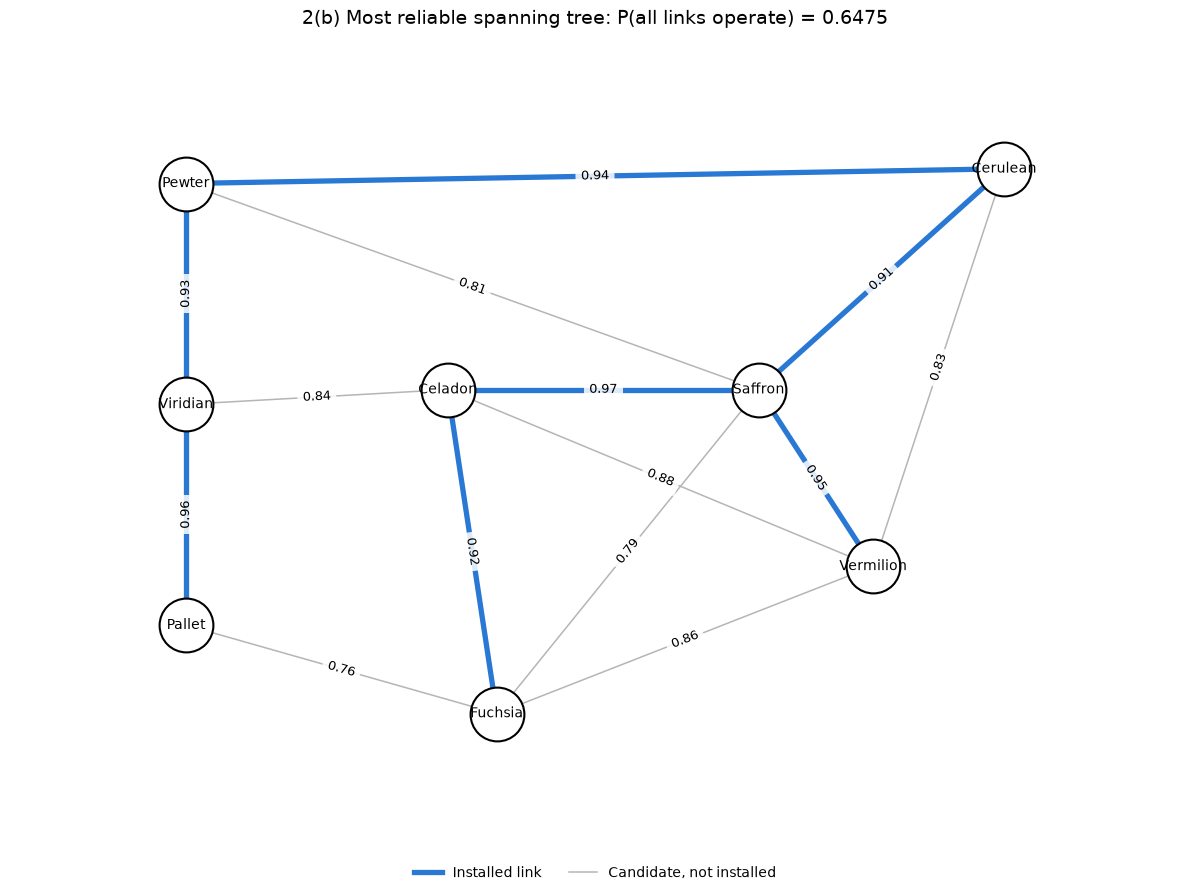

Locations: 8 | Candidate links: 14 | Installed links: 7
Joint probability: 0.647451 | Probability of failure: 35.25%


In [11]:

# Question 2(b): Most Reliable Spanning Tree
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

mst_orig, prob_orig, edges_orig = find_optimal_network(candidate_links)

G = nx.Graph()
G.add_weighted_edges_from(candidate_links, weight="probability")

pos = {
    "Pallet": (0, 0.5), "Viridian": (0, 2),
    "Pewter": (0, 3.5), "Cerulean": (5, 3.6),
    "Saffron": (3.5, 2.1), "Celadon": (1.6, 2.1),
    "Vermilion": (4.2, 0.9), "Fuchsia": (1.9, -0.1)
}

installed = list(mst_orig.edges())
unused = [(u, v) for u, v in G.edges() if not mst_orig.has_edge(u, v)]

fig, ax = plt.subplots(figsize=(12, 9))

# Draw candidate and installed links
for edges, color, width in [
    (unused, "#B5B5B5", 1.1),
    (installed, "#2878D4", 3.8)
]:
    nx.draw_networkx_edges(
        G, pos, edgelist=edges,
        edge_color=color, width=width, ax=ax
    )

nx.draw_networkx_nodes(
    G, pos, node_size=1500, node_color="white",
    edgecolors="black", linewidths=1.5, ax=ax
)
nx.draw_networkx_labels(G, pos, font_size=10, ax=ax)

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels={(u, v): f"{d['probability']:.2f}"
                 for u, v, d in G.edges(data=True)},
    font_size=9, rotate=True,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.85),
    ax=ax
)

ax.set_title(
    f"2(b) Most reliable spanning tree: P(all links operate) = {prob_orig:.4f}",
    fontsize=14, pad=20
)

ax.legend(
    handles=[
        Line2D([0], [0], color=c, lw=w, label=label)
        for c, w, label in [
            ("#2878D4", 3.8, "Installed link"),
            ("#B5B5B5", 1.1, "Candidate, not installed")
        ]
    ],
    loc="lower center", bbox_to_anchor=(0.5, -0.08),
    ncol=2, frameon=False
)

ax.axis("off")
ax.margins(0.15)
plt.tight_layout()
plt.show()

print(f"Locations: {G.number_of_nodes()} | "
      f"Candidate links: {G.number_of_edges()} | "
      f"Installed links: {mst_orig.number_of_edges()}")
print(f"Joint probability: {prob_orig:.6f} | "
      f"Probability of failure: {1 - prob_orig:.2%}")


## 2(c) Saffron-Celadon probability reduced to 0.75

,Link,p_e,w_e,Decision
0,Pallet-Viridian,0.96,0.040822,add
1,Saffron-Vermilion,0.95,0.051293,add
2,Pewter-Cerulean,0.94,0.061875,add
3,Viridian-Pewter,0.93,0.072571,add
4,Fuchsia-Celadon,0.92,0.083382,add
5,Cerulean-Saffron,0.91,0.094311,add
6,Celadon-Vermilion,0.88,0.127833,add


Links removed: Celadon-Saffron | Links added: Celadon-Vermilion
New optimal probability: 0.587378
Original tree with revised p: 0.500606
Change from 2(b): -0.060073


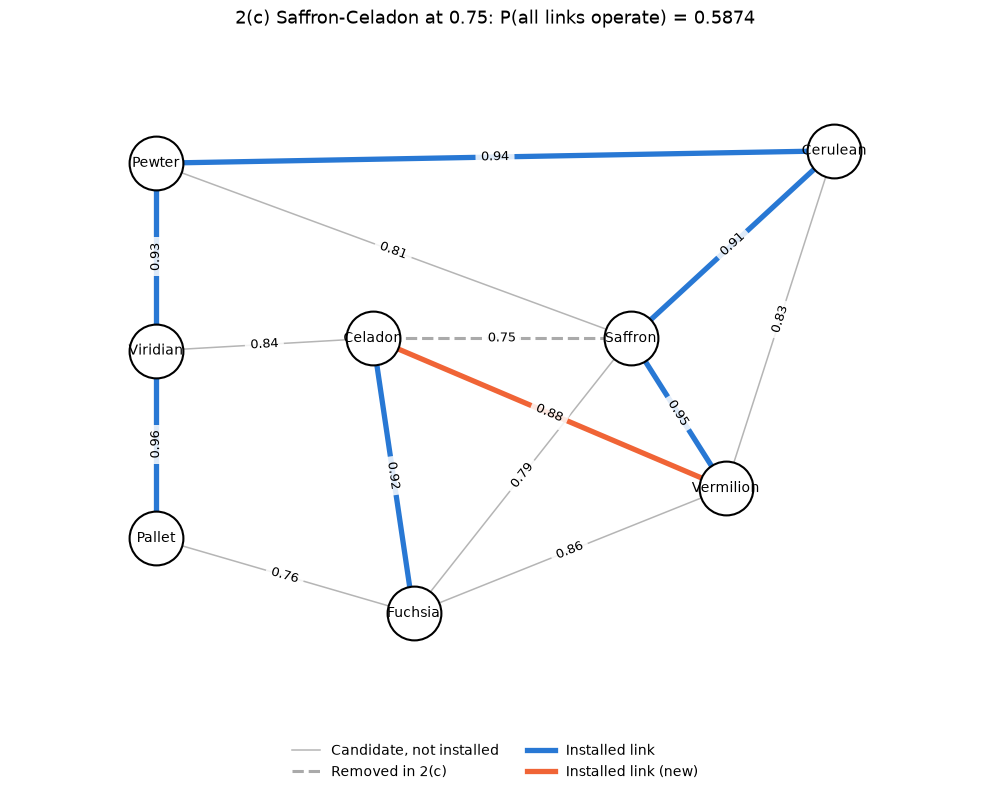

In [12]:

# Question 2(c): Saffron-Celadon reliability reduced to 0.75
import math

mst_orig, prob_orig, _ = find_optimal_network(candidate_links)

modified_links = [
    (u, v, 0.75 if {u, v} == {"Saffron", "Celadon"} else p)
    for u, v, p in candidate_links
]
mst_mod, prob_mod, edges_mod = find_optimal_network(modified_links)

# Compare original and modified spanning trees
edge_set = lambda G: {frozenset(e) for e in G.edges()}
original, modified = edge_set(mst_orig), edge_set(mst_mod)
added, removed = modified - original, original - modified
fmt = lambda edges: ", ".join("-".join(sorted(e)) for e in edges) or "None"

p_lookup = {frozenset((u, v)): p for u, v, p in modified_links}
prob_old_tree_new_p = math.prod(p_lookup[e] for e in original)

# Kruskal selected links table
df_kruskal_c = pd.DataFrame(edges_mod, columns=["From", "To", "p_e"])
df_kruskal_c["w_e"] = -np.log(df_kruskal_c["p_e"])
df_kruskal_c["Link"] = df_kruskal_c["From"] + "-" + df_kruskal_c["To"]
df_kruskal_c["Decision"] = "add"

display(
    df_kruskal_c.sort_values("w_e").reset_index(drop=True)
    [["Link", "p_e", "w_e", "Decision"]]
    .style.format({"p_e": "{:.2f}", "w_e": "{:.6f}"})
)

print(f"Links removed: {fmt(removed)} | Links added: {fmt(added)}")
print(f"New optimal probability: {prob_mod:.6f}")
print(f"Original tree with revised p: {prob_old_tree_new_p:.6f}")
print(f"Change from 2(b): {prob_mod - prob_orig:+.6f}")

# Plot modified network using the positions from 2(b)
G = nx.Graph()
G.add_weighted_edges_from(modified_links, weight="probability")

styles = [
    ("Candidate, not installed", "#B5B5B5", 1.1, "solid",
     lambda e: e not in original | modified),
    ("Removed in 2(c)", "#AAAAAA", 2.2, "dashed",
     lambda e: e in removed),
    ("Installed link", "#2878D4", 3.8, "solid",
     lambda e: e in original & modified),
    ("Installed link (new)", "#F06436", 3.8, "solid",
     lambda e: e in added)
]

fig, ax = plt.subplots(figsize=(10, 8))

for label, color, width, style, condition in styles:
    links = [(u, v) for u, v in G.edges()
             if condition(frozenset((u, v)))]
    nx.draw_networkx_edges(
        G, pos, edgelist=links, edge_color=color,
        width=width, style=style, ax=ax
    )

nx.draw_networkx_nodes(
    G, pos, node_size=1500, node_color="white",
    edgecolors="black", linewidths=1.5, ax=ax
)
nx.draw_networkx_labels(G, pos, font_size=10, ax=ax)
nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels={(u, v): f"{d['probability']:.2f}"
                 for u, v, d in G.edges(data=True)},
    font_size=9, rotate=True,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.85),
    ax=ax
)

ax.set_title(
    f"2(c) Saffron-Celadon at 0.75: P(all links operate) = {prob_mod:.4f}",
    fontsize=13, pad=20
)
ax.legend(
    handles=[Line2D([0], [0], color=c, lw=w, linestyle=s, label=label)
             for label, c, w, s, _ in styles],
    loc="lower center", bbox_to_anchor=(0.5, -0.12),
    ncol=2, frameon=False
)
ax.axis("off")
ax.margins(0.15)
plt.tight_layout()
plt.show()


## 2(b) & 2(c) Visualizing the Networks

Let's draw both the original optimal communication network and the modified network side-by-side to easily inspect the changes.


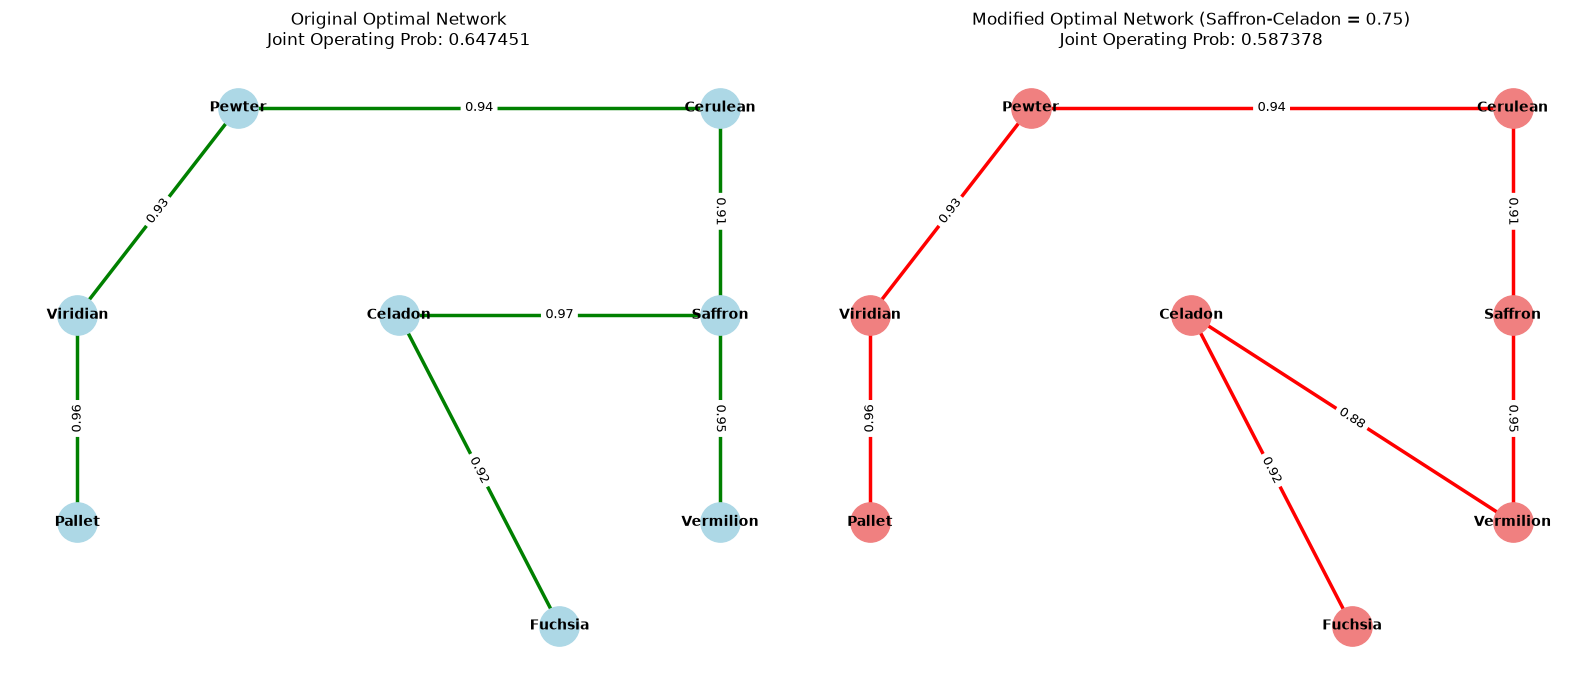

In [13]:
# Plotting the networks
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Fix layout/positions of the Kanto cities for consistent visualization
pos = {
    "Pewter": (1, 5),
    "Cerulean": (4, 5),
    "Celadon": (2, 3),
    "Saffron": (4, 3),
    "Vermilion": (4, 1),
    "Lavender": (5, 4), # Reference position
    "Fuchsia": (3, 0),
    "Viridian": (0, 3),
    "Pallet": (0, 1)
}

# Original network plot
plt.subplot(1, 2, 1)
nx.draw_networkx_nodes(mst_orig, pos, node_size=800, node_color='lightblue')
nx.draw_networkx_labels(mst_orig, pos, font_size=10, font_weight='bold')
edges = mst_orig.edges()
probabilities = [mst_orig[u][v]['probability'] for u, v in edges]
nx.draw_networkx_edges(mst_orig, pos, width=2.5, edge_color='green')
# Draw edge labels
edge_labels = {(u, v): f"{mst_orig[u][v]['probability']:.2f}" for u, v in edges}
nx.draw_networkx_edge_labels(mst_orig, pos, edge_labels=edge_labels, font_size=9)
plt.title(f"Original Optimal Network\nJoint Operating Prob: {prob_orig:.6f}", fontsize=12)
plt.axis('off')

# Modified network plot
plt.subplot(1, 2, 2)
nx.draw_networkx_nodes(mst_mod, pos, node_size=800, node_color='lightcoral')
nx.draw_networkx_labels(mst_mod, pos, font_size=10, font_weight='bold')
edges_m = mst_mod.edges()
probabilities_m = [mst_mod[u][v]['probability'] for u, v in edges_m]
nx.draw_networkx_edges(mst_mod, pos, width=2.5, edge_color='red')
edge_labels_m = {(u, v): f"{mst_mod[u][v]['probability']:.2f}" for u, v in edges_m}
nx.draw_networkx_edge_labels(mst_mod, pos, edge_labels=edge_labels_m, font_size=9)
plt.title(f"Modified Optimal Network (Saffron-Celadon = 0.75)\nJoint Operating Prob: {prob_mod:.6f}", fontsize=12)
plt.axis('off')

plt.tight_layout()
plt.show()

## Summary of Solutions & Interpretation (Question 2)

### (b) Original Network Results
* **Maximized Probability of All Links Operating:** **0.647451** (64.75% chance that all links remain intact during the storm).
* **Selected Links (7 links total to span the 8 locations):**
  * **Pallet $\leftrightarrow$ Viridian** ($p = 0.96$)
  * **Viridian $\leftrightarrow$ Pewter** ($p = 0.93$)
  * **Pewter $\leftrightarrow$ Cerulean** ($p = 0.94$)
  * **Cerulean $\leftrightarrow$ Saffron** ($p = 0.91$)
  * **Saffron $\leftrightarrow$ Celadon** ($p = 0.97$)
  * **Saffron $\leftrightarrow$ Vermilion** ($p = 0.95$)
  * **Celadon $\leftrightarrow$ Fuchsia** ($p = 0.92$)

---

### (c) Scenario: Saffron–Celadon Operating Probability drops to 0.75

* **New Maximized Probability of All Links Operating:** **0.587378** (58.74% chance that all links remain intact during the storm).
* **Selected Links:**
  * **Pallet $\leftrightarrow$ Viridian** ($p = 0.96$)
  * **Viridian $\leftrightarrow$ Pewter** ($p = 0.93$)
  * **Pewter $\leftrightarrow$ Cerulean** ($p = 0.94$)
  * **Cerulean $\leftrightarrow$ Saffron** ($p = 0.91$)
  * **Saffron $\leftrightarrow$ Vermilion** ($p = 0.95$)
  * **Celadon $\leftrightarrow$ Fuchsia** ($p = 0.92$)
  * **Celadon $\leftrightarrow$ Vermilion** ($p = 0.88$)

#### Identification of Network Changes:
1. **Dropped Link**: **Saffron $\leftrightarrow$ Celadon** ($p = 0.97 \rightarrow 0.75$).
2. **Added Link**: **Celadon $\leftrightarrow$ Vermilion** ($p = 0.88$).

#### Interpretation:
When the operating reliability of the Saffron–Celadon link drops from a very reliable 0.97 to 0.75, keeping it in the network would severely degrade overall system reliability. To preserve connectivity while maximizing the probability of uninterrupted operations, the algorithm replaces this now unreliable link with the next best alternative that avoids cycles. This alternative is the **Celadon $\leftrightarrow$ Vermilion** link ($p = 0.88$). This structural adjustment keeps all 8 sites connected while keeping the total reliability as high as possible (dropping only to 58.74% instead of plunging to 50.06% if we had kept the degraded link).
```

# Question 3: Planning a Pokémon Rescue Expedition

## 3(a) Binary Integer Linear Programming Formulation

### Sets and Indices
- Let $I$ be the set of available Pokémon: $\{1: \text{Charizard}, 2: \text{Blastoise}, 3: \text{Pikachu}, 4: \text{Raichu}, 5: \text{Pidgeot}, 6: \text{Machamp}, 7: \text{Lapras}\}$.
- Let $J$ be the set of candidate outposts: $\{1: \text{Viridian Forest}, 2: \text{Mt. Moon}, 3: \text{Seafoam Islands}\}$.

### Given Parameters
- $R_{i,j}$: Rescue points of Pokémon $i$ at outpost $j$ (from Table 3).
- $D_i$: Deployment cost of Pokémon $i$ (from Table 3).
- $O_j$: Opening cost of outpost $j$: $O_1 = 6, O_2 = 8, O_3 = 9$.
- $F$: Cost of a fire-safety kit ($F = 2$ credits).
- $B$: Total budget ($B = 50$ credits).

### Decision Variables
- $y_j \in \{0, 1\}$: 1 if outpost $j$ is opened, 0 otherwise.
- $x_{i,j} \in \{0, 1\}$: 1 if Pokémon $i$ is assigned to outpost $j$, 0 otherwise.
- $z_i \in \{0, 1\}$: 1 if Pokémon $i$ is deployed (to any outpost), 0 otherwise.
- $f_j \in \{0, 1\}$: 1 if a fire-safety kit is installed at outpost $j$, 0 otherwise.

### Objective Function
Maximize total rescue points:
$$\max \sum_{i \in I} \sum_{j \in J} R_{i,j} x_{i,j}$$

### Constraints
1. **Pokémon Deployment and Single Assignment Linking**:
   A Pokémon can be assigned to at most one outpost, and only if it is deployed:
   $$\sum_{j \in J} x_{i,j} = z_i \quad \forall i \in I$$
   *(Note: This naturally restricts each Pokémon to at most one outpost and sets $z_i = 1$ if assigned, otherwise $z_i = 0$.)*

2. **Budget Constraint**:
   Total cost (outpost opening + Pokémon deployment + fire-safety kits) must not exceed 50 credits:
   $$\sum_{j \in J} O_j y_j + \sum_{i \in I} D_i z_i + \sum_{j \in J} F f_j \le 50$$

3. **Outpost Capacity and Open Linking**:
   Open at least two outposts:
   $$\sum_{j \in J} y_j \ge 2$$
   Each open outpost must have between 2 and 3 Pokémon, and a closed outpost must have none:
   $$2 y_j \le \sum_{i \in I} x_{i,j} \le 3 y_j \quad \forall j \in J$$

4. **Pikachu and Raichu Co-existence**:
   At most one of Pikachu ($i=3$) and Raichu ($i=4$) may be deployed:
   $$z_3 + z_4 \le 1$$

5. **Charizard Backup Rule**:
   If Charizard ($i=1$) is assigned to outpost $j$, Blastoise ($i=2$) or Lapras ($i=7$) must also be assigned to outpost $j$:
   $$x_{1,j} \le x_{2,j} + x_{7,j} \quad \forall j \in J$$

6. **Seafoam Islands ($j=3$) Opening Condition**:
   Seafoam Islands can open only if Lapras ($i=7$) is assigned there:
   $$y_3 \le x_{7,3}$$

7. **Fire-safety Kit "If and Only If" Rule**:
   A fire-safety kit is installed at outpost $j$ if and only if Charizard ($i=1$) is assigned there. This bidirectional logical requirement translates to the following equality constraint:
   $$f_j = x_{1,j} \quad \forall j \in J$$
   
   *Explanation*: Since $f_j$ and $x_{1,j}$ are binary, setting them equal ensures that if Charizard is assigned to outpost $j$ ($x_{1,j} = 1$), a kit must be installed ($f_j = 1$). If Charizard is not assigned ($x_{1,j} = 0$), a kit cannot be installed ($f_j = 0$).


## 3(b) Solution

In [14]:
import pulp
import pandas as pd

# Data definition
pokemon_names = ["Charizard", "Blastoise", "Pikachu", "Raichu", "Pidgeot", "Machamp", "Lapras"]
outpost_names = ["Viridian Forest", "Mt. Moon", "Seafoam Islands"]

# Rescue points (rows: Pokemon, cols: Outposts)
rescue_points = {
    "Charizard": [11, 13, 4],
    "Blastoise": [8, 7, 12],
    "Pikachu": [10, 8, 6],
    "Raichu": [9, 10, 7],
    "Pidgeot": [10, 9, 7],
    "Machamp": [7, 12, 6],
    "Lapras": [5, 6, 14]
}

deployment_cost = {
    "Charizard": 4, "Blastoise": 4, "Pikachu": 3, "Raichu": 3, "Pidgeot": 3, "Machamp": 5, "Lapras": 4
}

outpost_opening_cost = {
    "Viridian Forest": 6, "Mt. Moon": 8, "Seafoam Islands": 9
}

kit_cost = 2
budget = 50

def solve_rescue_model(include_backup_rule=True):
    prob = pulp.LpProblem("Pokemon_Rescue_Expedition", pulp.LpMaximize)

    # Decision Variables
    y = pulp.LpVariable.dicts("y", outpost_names, cat="Binary")
    x = pulp.LpVariable.dicts("x", ((i, j) for i in pokemon_names for j in outpost_names), cat="Binary")
    z = pulp.LpVariable.dicts("z", pokemon_names, cat="Binary")
    f = pulp.LpVariable.dicts("f", outpost_names, cat="Binary")

    # Objective Function: Maximize Rescue Points
    prob += pulp.lpSum(rescue_points[i][j_idx] * x[i, j]
                       for i in pokemon_names for j_idx, j in enumerate(outpost_names))

    # Constraints

    # 1. Assignment linking and single assignment
    for i in pokemon_names:
        prob += pulp.lpSum(x[i, j] for j in outpost_names) == z[i]

    # 2. Budget constraint
    total_cost_expr = (
        pulp.lpSum(outpost_opening_cost[j] * y[j] for j in outpost_names) +
        pulp.lpSum(deployment_cost[i] * z[i] for i in pokemon_names) +
        pulp.lpSum(kit_cost * f[j] for j in outpost_names)
    )
    prob += total_cost_expr <= budget

    # 3. Outpost counts and capacity linking
    prob += pulp.lpSum(y[j] for j in outpost_names) >= 2
    for j in outpost_names:
        prob += pulp.lpSum(x[i, j] for i in pokemon_names) >= 2 * y[j]
        prob += pulp.lpSum(x[i, j] for i in pokemon_names) <= 3 * y[j]

    # 4. Pikachu and Raichu limitation
    prob += z["Pikachu"] + z["Raichu"] <= 1

    # 5. Charizard backup rule
    if include_backup_rule:
        for j in outpost_names:
            prob += x["Charizard", j] <= x["Blastoise", j] + x["Lapras", j]

    # 6. Seafoam Islands opening condition
    prob += y["Seafoam Islands"] <= x["Lapras", "Seafoam Islands"]

    # 7. Fire-safety kit iff rule
    for j in outpost_names:
        prob += f[j] == x["Charizard", j]

    prob.solve(pulp.PULP_CBC_CMD(msg=False))

    return prob, y, x, z, f, total_cost_expr

# Solve Part (b)
prob_b, y_b, x_b, z_b, f_b, cost_expr_b = solve_rescue_model(include_backup_rule=True)

print("--- Part (b) Results ---")
print(f"Optimization Status: {pulp.LpStatus[prob_b.status]}")
print(f"Maximum Rescue Points: {pulp.value(prob_b.objective)}")
print(f"Total Cost incurred: {pulp.value(cost_expr_b)} credits\n")

print("Open Outposts & Installed Fire-safety Kits:")
for j in outpost_names:
    if y_b[j].varValue > 0.5:
        kit_installed = "Yes" if f_b[j].varValue > 0.5 else "No"
        print(f"  * {j} (Open, Fire-safety Kit: {kit_installed})")

print("\nPokémon Assignments:")
for j in outpost_names:
    if y_b[j].varValue > 0.5:
        assigned_poks = [i for i in pokemon_names if x_b[i, j].varValue > 0.5]
        print(f"  * {j} has: {', '.join(assigned_poks)}")

--- Part (b) Results ---
Optimization Status: Optimal
Maximum Rescue Points: 62.0
Total Cost incurred: 48.0 credits

Open Outposts & Installed Fire-safety Kits:
  * Viridian Forest (Open, Fire-safety Kit: Yes)
  * Mt. Moon (Open, Fire-safety Kit: No)
  * Seafoam Islands (Open, Fire-safety Kit: No)

Pokémon Assignments:
  * Viridian Forest has: Charizard, Blastoise
  * Mt. Moon has: Raichu, Machamp
  * Seafoam Islands has: Pidgeot, Lapras


In [15]:

# Part (b): Rescue plan with Charizard backup rule
prob_b, y_b, x_b, z_b, f_b, cost_expr_b = solve_rescue_model(True)
assert pulp.LpStatus[prob_b.status] == "Optimal"

rows = []
for j_idx, j in enumerate(outpost_names):
    if y_b[j].varValue < 0.5:
        continue

    team = [i for i in pokemon_names if x_b[i, j].varValue > 0.5]
    kit = f_b[j].varValue > 0.5
    opening = outpost_opening_cost[j]
    deployment = sum(deployment_cost[i] for i in team)
    kit_total = kit_cost * int(kit)

    rows.append({
        "Outpost": j, "Open": True, "Pokémon": ", ".join(team),
        "Kit": kit, "Points": sum(rescue_points[i][j_idx] for i in team),
        "Opening cost": opening, "Deployment cost": deployment,
        "Kit cost": kit_total,
        "Outpost total cost": opening + deployment + kit_total
    })

df_results_b = pd.DataFrame(rows).set_index("Outpost")
display(df_results_b)

points, cost = df_results_b["Points"].sum(), df_results_b["Outpost total cost"].sum()
assert abs(points - pulp.value(prob_b.objective)) < 1e-6
assert abs(cost - pulp.value(cost_expr_b)) < 1e-6

print(f"Maximum rescue points: {points}")
print(f"Total cost: {cost} credits | Budget remaining: {budget - cost} credits")
print("Solution verified.")


,Open,Pokémon,Kit,Points,Opening cost,Deployment cost,Kit cost,Outpost total cost
Outpost,,,,,,,,
Viridian Forest,True,"Charizard, Blastoise",True,19,6,8,2,16
Mt. Moon,True,"Raichu, Machamp",False,22,8,8,0,16
Seafoam Islands,True,"Pidgeot, Lapras",False,21,9,7,0,16


Maximum rescue points: 62
Total cost: 48 credits | Budget remaining: 2 credits
Solution verified.


## 3(c) Charizard backup requirement removed

Only constraint (5) is dropped. The kit rule (7) and all other constraints stay in place.

In [16]:
# Solve Part (c) - Without Charizard Backup requirement
prob_c, y_c, x_c, z_c, f_c, cost_expr_c = solve_rescue_model(include_backup_rule=False)

print("--- Part (c) Results (Without Charizard Backup Constraint) ---")
print(f"Optimization Status: {pulp.LpStatus[prob_c.status]}")
print(f"Maximum Rescue Points: {pulp.value(prob_c.objective)}")
print(f"Total Cost incurred: {pulp.value(cost_expr_c)} credits\n")

print("Open Outposts & Installed Fire-safety Kits:")
for j in outpost_names:
    if y_c[j].varValue > 0.5:
        kit_installed = "Yes" if f_c[j].varValue > 0.5 else "No"
        print(f"  * {j} (Open, Fire-safety Kit: {kit_installed})")

print("\nPokémon Assignments:")
for j in outpost_names:
    if y_c[j].varValue > 0.5:
        assigned_poks = [i for i in pokemon_names if x_c[i, j].varValue > 0.5]
        print(f"  * {j} has: {', '.join(assigned_poks)}")

--- Part (c) Results (Without Charizard Backup Constraint) ---
Optimization Status: Optimal
Maximum Rescue Points: 71.0
Total Cost incurred: 48.0 credits

Open Outposts & Installed Fire-safety Kits:
  * Viridian Forest (Open, Fire-safety Kit: No)
  * Mt. Moon (Open, Fire-safety Kit: Yes)
  * Seafoam Islands (Open, Fire-safety Kit: No)

Pokémon Assignments:
  * Viridian Forest has: Pikachu, Pidgeot
  * Mt. Moon has: Charizard, Machamp
  * Seafoam Islands has: Blastoise, Lapras


In [17]:

# Part (c): Rescue plan without Charizard backup rule
prob_c, y_c, x_c, z_c, f_c, cost_expr_c = solve_rescue_model(False)
assert pulp.LpStatus[prob_c.status] == "Optimal"

rows = []
for j_idx, j in enumerate(outpost_names):
    if y_c[j].varValue < 0.5:
        continue

    team = [i for i in pokemon_names if x_c[i, j].varValue > 0.5]
    kit = f_c[j].varValue > 0.5
    opening = outpost_opening_cost[j]
    deployment = sum(deployment_cost[i] for i in team)
    kit_total = kit_cost * int(kit)

    rows.append({
        "Outpost": j, "Open": True, "Pokémon": ", ".join(team),
        "Kit": kit, "Points": sum(rescue_points[i][j_idx] for i in team),
        "Opening cost": opening, "Deployment cost": deployment,
        "Kit cost": kit_total,
        "Outpost total cost": opening + deployment + kit_total
    })

df_results_c = pd.DataFrame(rows).set_index("Outpost")
display(df_results_c)

points, cost = df_results_c["Points"].sum(), df_results_c["Outpost total cost"].sum()
assert abs(points - pulp.value(prob_c.objective)) < 1e-6
assert abs(cost - pulp.value(cost_expr_c)) < 1e-6

print(f"Maximum rescue points: {points}")
print(f"Total cost: {cost} credits | Budget remaining: {budget - cost} credits")
print("Solution verified.")


,Open,Pokémon,Kit,Points,Opening cost,Deployment cost,Kit cost,Outpost total cost
Outpost,,,,,,,,
Viridian Forest,True,"Pikachu, Pidgeot",False,20,6,6,0,12
Mt. Moon,True,"Charizard, Machamp",True,25,8,9,2,19
Seafoam Islands,True,"Blastoise, Lapras",False,26,9,8,0,17


Maximum rescue points: 71
Total cost: 48 credits | Budget remaining: 2 credits
Solution verified.


In [18]:

# Question 3: Compare optimal rescue plans

def summarise(prob, x, f, cost):
    assigned = {
        j: [i for i in pokemon_names if x[i, j].varValue > 0.5]
        for j in outpost_names
    }
    deployed = {i for team in assigned.values() for i in team}

    return {
        **{j: ", ".join(team) or "-" for j, team in assigned.items()},
        "Not deployed": ", ".join(i for i in pokemon_names if i not in deployed) or "-",
        "Kit at": ", ".join(j for j in outpost_names if f[j].varValue > 0.5) or "-",
        "Total cost": round(pulp.value(cost)),
        "Rescue points": round(pulp.value(prob.objective))
    }

comparison_q3 = pd.DataFrame({
    "3(b) with backup rule": summarise(prob_b, x_b, f_b, cost_expr_b),
    "3(c) without backup rule": summarise(prob_c, x_c, f_c, cost_expr_c)
})

change = comparison_q3.loc["Rescue points"].diff().iloc[-1]
comparison_q3.loc["Change in points"] = ["-", f"{change:+.0f}"]

display(comparison_q3)


,3(b) with backup rule,3(c) without backup rule
Viridian Forest,"Charizard, Blastoise","Pikachu, Pidgeot"
Mt. Moon,"Raichu, Machamp","Charizard, Machamp"
Seafoam Islands,"Pidgeot, Lapras","Blastoise, Lapras"
Not deployed,Pikachu,Raichu
Kit at,Viridian Forest,Mt. Moon
Total cost,48,48
Rescue points,62,71
Change in points,-,+9


## Summary of Solutions & Interpretation (Question 3)

### (a) Explaining the "If and Only If" Rule for Fire-Safety Kits
A fire-safety kit must be installed at an outpost $j$ **if and only if** Charizard ($i=1$) is assigned to that outpost. This represents a bidirectional implication:
1. If Charizard is assigned to outpost $j$ ($x_{1,j} = 1$), then a fire-safety kit must be installed ($f_j = 1$).
2. If Charizard is not assigned to outpost $j$ ($x_{1,j} = 0$), then a fire-safety kit cannot be installed ($f_j = 0$).

Because $f_j$ and $x_{1,j}$ are both binary variables $\in \{0, 1\}$, we can enforce both conditions simultaneously using a single equality constraint:
$$f_j = x_{1,j} \quad \forall j \in J$$
This equality perfectly ensures that both variables always share the same value, representing the bidirectional "if and only if" condition without requiring complex conditional inequalities.

---

### (b) Optimal Rescue Plan with Backup Constraint

* **Maximum Rescue Points:** **62.0**
* **Total Cost Incurred:** **48.0 credits** (out of 50)
  - *Cost Breakdown*: Opening Viridian Forest (6) + Mt. Moon (8) + Seafoam Islands (9) + Deploying 6 Pokémon (4+4+3+3+5+4 = 23) + 1 Fire-safety kit (2) = 48 credits.
* **Outpost and Equipment Plan**:
  - **Viridian Forest**: Open, **Fire-safety Kit Installed** (due to Charizard).
  - **Mt. Moon**: Open, No Kit.
  - **Seafoam Islands**: Open, No Kit (Lapras assigned here to satisfy the opening condition).
* **Pokémon Assignments**:
  - **Viridian Forest**: Charizard, Blastoise (satisfies the backup requirement since Blastoise accompanies Charizard).
  - **Mt. Moon**: Raichu, Machamp.
  - **Seafoam Islands**: Pidgeot, Lapras.

---

### (c) Optimal Rescue Plan Without Backup Constraint
When we remove the backup requirement (that Charizard must be accompanied by Blastoise or Lapras at the same outpost), we resolve the model and get:

* **Maximum Rescue Points:** **71.0** (an increase of **9.0 points**).
* **Total Cost Incurred:** **48.0 credits**.
* **Outpost and Equipment Plan**:
  - **Viridian Forest**: Open, No Kit.
  - **Mt. Moon**: Open, **Fire-safety Kit Installed** (due to Charizard).
  - **Seafoam Islands**: Open, No Kit.
* **Pokémon Assignments**:
  - **Viridian Forest**: Pikachu, Pidgeot.
  - **Mt. Moon**: Charizard, Machamp.
  - **Seafoam Islands**: Blastoise, Lapras.

#### Comparison and Insights:
* **Score Improvement**: Removing the constraint allowed the total rescue score to jump from **62.0 to 71.0**.
* **Assignment Re-allocation**: Without the backup constraint, **Charizard is reassigned to Mt. Moon** where its rescue contribution is higher (13 points vs 11 in Viridian Forest), and it is partnered with **Machamp** instead of being restricted to Blastoise or Lapras. Consequently, the fire-safety kit constraint moves the kit from Viridian Forest to Mt. Moon.
* **Pikachu Deployment**: This structural shift also allows **Pikachu** to be deployed at Viridian Forest instead of Raichu at Mt. Moon, leading to a much more optimal scoring configuration overall while staying within the same 48-credit budget limit.
